In [1]:
import pandas as pd
import scanpy as sc
import sys
from pathlib import Path
import numpy as np
from scipy.stats import f_oneway
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Add the IDEAS repo root to Python's import path
repo_root = Path("/home/csb/Saloni/IDEAS_ID/IDEAS")
sys.path.append(str(repo_root))

from computeID.functions_IDEAS import compute_ID

/home/csb/Saloni/IDEAS_ID/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
adata = sc.read('/home/csb/Saloni/IDEAS_ID/IDEAS/Data/preprocessed_adata.h5ad')

print(adata)

AnnData object with n_obs × n_vars = 16822 × 5000
    obs: 'sample', 'clusters', 'prior_time', 'librarysize'
    var: 'gene_ids', 'feature_types', 'genome', 'means', 'dispersions', 'dispersions_norm'
    uns: 'clusters_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap', 'X_umap_rna_unintegrated'
    varm: 'PCs'
    layers: 'raw', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'


In [4]:
id_results = compute_ID(
    adata,
    group="clusters",
    method="2nn",
    n_samples=30,
    sample_size=0,
    normalization=True,
    full_output=True,
    id_score=True
)

/home/csb/Saloni/IDEAS_ID/IDEAS/computeID/functions_IDEAS.py:41: UserWarning: 'sample_size' not specified: automatically set to 191 (80% of smallest group size: 16822)
  warnings.warn(f"'sample_size' not specified: automatically set to {sample_size} (80% of smallest group size: {n_obs})")
Computing Intrinsic Dimension:   0%|          | 0/12 [00:00<?, ?it/s]

Computing ID for clusters Alpha:


Computing Intrinsic Dimension:   8%|▊         | 1/12 [00:00<00:03,  2.86it/s]

Computing ID for clusters Beta:


Computing Intrinsic Dimension:  17%|█▋        | 2/12 [00:00<00:03,  3.02it/s]

...

Computing Intrinsic Dimension:  83%|████████▎ | 10/12 [00:03<00:00,  3.18it/s]

Computing ID for clusters Ngn3 low:


Computing Intrinsic Dimension:  92%|█████████▏| 11/12 [00:03<00:00,  3.15it/s]

Computing ID for clusters Prlf. Ductal:


Computing Intrinsic Dimension: 100%|██████████| 12/12 [00:03<00:00,  3.17it/s]


In [5]:
print(id_results.shape)
display(id_results.head())

(30, 12)


,Alpha,Beta,Delta,Ductal,Epsilon,Fev+,Fev+ Alpha,Fev+ Beta,Fev+ Delta,Ngn3 high,Ngn3 low,Prlf. Ductal
1,0.776889,0.365468,0.050332,0.351567,0.365041,0.368075,0.270968,0.050060,0.445193,0.468348,0.233082,0.483635
2,0.653926,0.118785,0.074926,0.415974,0.159655,0.101238,0.519984,0.502380,0.407123,0.681973,0.328698,0.420598
3,0.221317,0.638635,0.069534,0.473840,0.275205,0.651645,0.631397,0.316490,0.610921,0.454603,0.441840,0.553464
4,0.406401,0.328538,0.790289,0.289679,0.341009,0.747852,0.167133,0.343704,0.456827,0.223474,0.503216,0.342316
5,0.602932,0.097808,0.072461,0.276230,0.249085,0.200293,0.162686,0.399792,0.456459,0.364551,0.263413,0.277395


In [6]:
id_summary = pd.DataFrame({
    "clusters": id_results.columns,
    "ID": id_results.mean(axis=0),
    "SD": id_results.std(axis=0)
})

display(id_summary)

,clusters,ID,SD
Alpha,Alpha,0.415935,0.197334
Beta,Beta,0.385965,0.181382
Delta,Delta,0.141323,0.199915
Ductal,Ductal,0.361644,0.187394
Epsilon,Epsilon,0.313325,0.088857
Fev+,Fev+,0.356590,0.233225
Fev+ Alpha,Fev+ Alpha,0.319830,0.173624
Fev+ Beta,Fev+ Beta,0.344062,0.194613
Fev+ Delta,Fev+ Delta,0.459809,0.082456
Ngn3 high,Ngn3 high,0.372204,0.202110


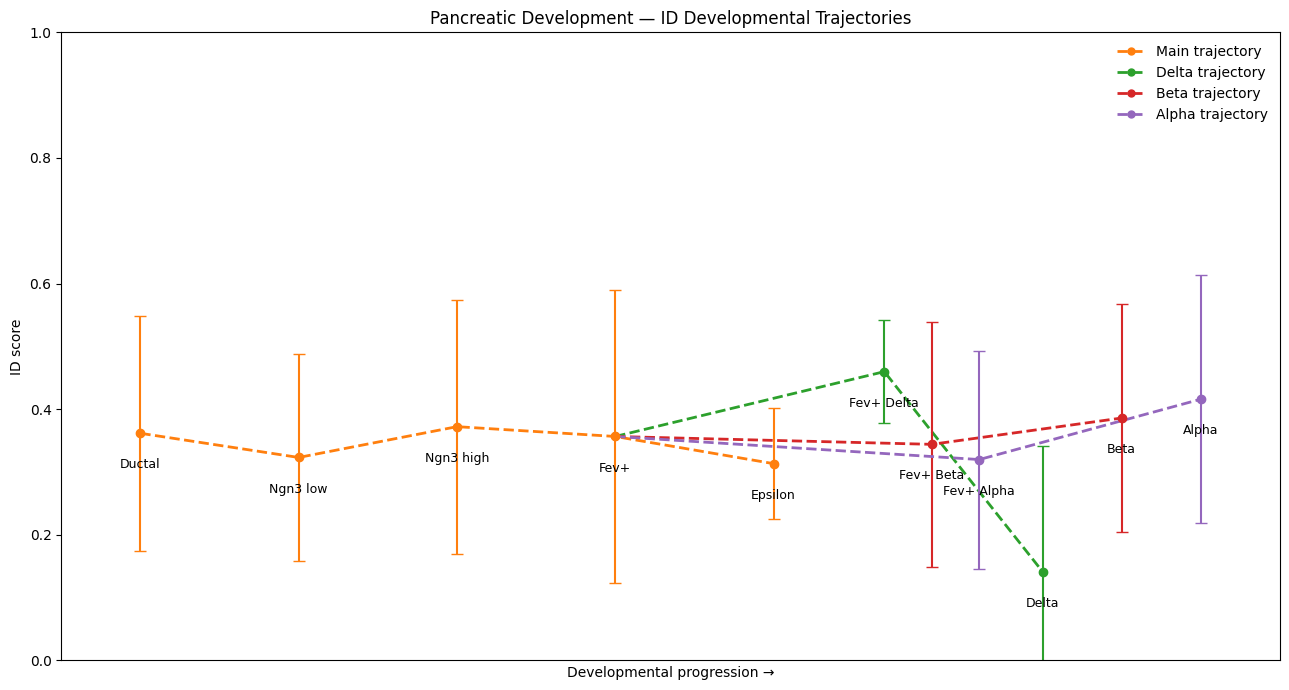

In [7]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DEVELOPMENTAL ORDER
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+",
    "Epsilon",
    "Fev+ Delta",
    "Delta",
    "Fev+ Beta",
    "Beta",
    "Fev+ Alpha",
    "Alpha"
]


# ============================================================
# MAKE LOOKUP DICTIONARIES FROM id_summary
# ============================================================

id_mean = (
    id_summary
    .set_index("clusters")["ID"]
    .to_dict()
)

id_sd = (
    id_summary
    .set_index("clusters")["SD"]
    .to_dict()
)


# ============================================================
# X POSITIONS
# These are ONLY for the developmental layout.
# Y = actual ID score.
# ============================================================

x = {

    # Main trajectory
    "Ductal":       0.0,
    "Ngn3 low":     1.0,
    "Ngn3 high":    2.0,
    "Fev+":         3.0,
    "Epsilon":      4.0,

    # Delta branch
    "Fev+ Delta":   4.7,
    "Delta":        5.7,

    # Beta branch
    "Fev+ Beta":    5.0,
    "Beta":         6.2,

    # Alpha branch
    "Fev+ Alpha":   5.3,
    "Alpha":        6.7,
}


# ============================================================
# TRAJECTORY COLORS
# ============================================================

colors = {
    "main":  "tab:orange",
    "delta": "tab:green",
    "beta":  "tab:red",
    "alpha": "tab:purple"
}


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))


# ============================================================
# HELPER: PLOT ONE ID POINT + ERROR BAR
# ============================================================

def plot_id_point(name, color):

    if name not in id_mean:
        return

    ax.errorbar(
        x[name],
        id_mean[name],
        yerr=id_sd[name],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=4,
        markersize=6,
        linewidth=1.5
    )


# ============================================================
# MAIN TRAJECTORY
#
# Ductal → Ngn3 low → Ngn3 high → Fev+ → Epsilon
#
# Fev+ is plotted HERE and therefore gets the main/orange color.
# ============================================================

main_path = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+",
    "Epsilon"
]

# Main trajectory line
ax.plot(
    [x[name] for name in main_path],
    [id_mean[name] for name in main_path],
    "o--",
    color=colors["main"],
    linewidth=2,
    markersize=5,
    label="Main trajectory"
)

# Main trajectory points + error bars
for name in main_path:
    plot_id_point(name, colors["main"])


# ============================================================
# DELTA BRANCH
#
# Fev+ → Fev+ Delta → Delta
#
# IMPORTANT:
# Fev+ is NOT plotted again.
# Only the branch-specific points are green.
# ============================================================

delta_branch = [
    "Fev+ Delta",
    "Delta"
]

# Branch line INCLUDING Fev+ as the starting coordinate
delta_line = [
    "Fev+",
    "Fev+ Delta",
    "Delta"
]

ax.plot(
    [x[name] for name in delta_line],
    [id_mean[name] for name in delta_line],
    "o--",
    color=colors["delta"],
    linewidth=2,
    markersize=5,
    label="Delta trajectory"
)

# Plot only branch-specific points
for name in delta_branch:
    plot_id_point(name, colors["delta"])


# ============================================================
# BETA BRANCH
#
# Fev+ → Fev+ Beta → Beta
# ============================================================

beta_branch = [
    "Fev+ Beta",
    "Beta"
]

beta_line = [
    "Fev+",
    "Fev+ Beta",
    "Beta"
]

ax.plot(
    [x[name] for name in beta_line],
    [id_mean[name] for name in beta_line],
    "o--",
    color=colors["beta"],
    linewidth=2,
    markersize=5,
    label="Beta trajectory"
)

# Plot only branch-specific points
for name in beta_branch:
    plot_id_point(name, colors["beta"])


# ============================================================
# ALPHA BRANCH
#
# Fev+ → Fev+ Alpha → Alpha
# ============================================================

alpha_branch = [
    "Fev+ Alpha",
    "Alpha"
]

alpha_line = [
    "Fev+",
    "Fev+ Alpha",
    "Alpha"
]

ax.plot(
    [x[name] for name in alpha_line],
    [id_mean[name] for name in alpha_line],
    "o--",
    color=colors["alpha"],
    linewidth=2,
    markersize=5,
    label="Alpha trajectory"
)

# Plot only branch-specific points
for name in alpha_branch:
    plot_id_point(name, colors["alpha"])


# ============================================================
# LABELS
# ============================================================

# Slightly different offsets to prevent nearby labels
# from overlapping.

label_offset = {

    "Ductal":       -0.04,
    "Ngn3 low":     -0.04,
    "Ngn3 high":    -0.04,
    "Fev+":         -0.04,
    "Epsilon":      -0.04,

    "Fev+ Delta":   -0.04,
    "Delta":        -0.04,

    "Fev+ Beta":    -0.04,
    "Beta":         -0.04,

    "Fev+ Alpha":   -0.04,
    "Alpha":        -0.04,
}


for name in cluster:

    if name not in id_mean:
        continue

    ax.text(
        x[name],
        id_mean[name] + label_offset[name],
        name,
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-0.5, 7.2)

ax.set_xticks([])

ax.set_xlabel("Developmental progression →")

ax.set_ylabel("ID score")

# ID is normalized between 0 and 1
ax.set_ylim(0, 1)

ax.set_title(
    "Pancreatic Development — ID Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()

plt.show()

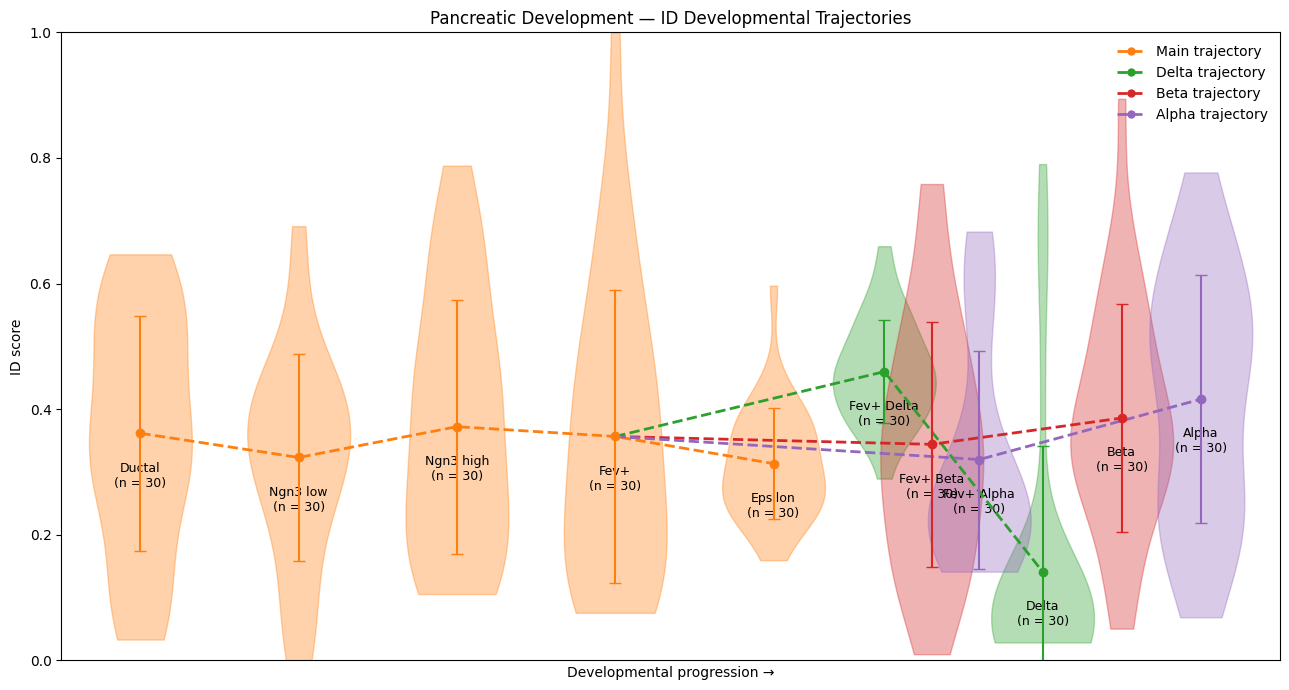

In [8]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DEVELOPMENTAL ORDER
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+",
    "Epsilon",
    "Fev+ Delta",
    "Delta",
    "Fev+ Beta",
    "Beta",
    "Fev+ Alpha",
    "Alpha"
]


# ============================================================
# ID MEAN + SD
# ============================================================

id_mean = (
    id_summary
    .set_index("clusters")["ID"]
    .to_dict()
)

id_sd = (
    id_summary
    .set_index("clusters")["SD"]
    .to_dict()
)


# ============================================================
# CELL-LEVEL ID DISTRIBUTIONS
#
# id_results has:
#   rows    = individual ID calculations
#   columns = clusters
# ============================================================

id_groups = {
    name: id_results[name].dropna().values
    for name in cluster
    if name in id_results.columns
}


# ============================================================
# NUMBER OF CELLS / ID VALUES
# ============================================================

cell_counts = {
    name: len(id_groups[name])
    for name in id_groups
}


# ============================================================
# X POSITIONS
#
# These are ONLY used to create the developmental layout.
# ============================================================

x = {

    # Main trajectory
    "Ductal":       0.0,
    "Ngn3 low":     1.0,
    "Ngn3 high":    2.0,
    "Fev+":         3.0,
    "Epsilon":      4.0,

    # Delta branch
    "Fev+ Delta":   4.7,
    "Delta":        5.7,

    # Beta branch
    "Fev+ Beta":    5.0,
    "Beta":         6.2,

    # Alpha branch
    "Fev+ Alpha":   5.3,
    "Alpha":        6.7,
}


# ============================================================
# TRAJECTORY COLORS
# ============================================================

colors = {
    "main":  "tab:orange",
    "delta": "tab:green",
    "beta":  "tab:red",
    "alpha": "tab:purple"
}


# ============================================================
# ASSIGN EACH CLUSTER TO A TRAJECTORY
# ============================================================

trajectory = {

    # Main
    "Ductal": "main",
    "Ngn3 low": "main",
    "Ngn3 high": "main",
    "Fev+": "main",
    "Epsilon": "main",

    # Delta
    "Fev+ Delta": "delta",
    "Delta": "delta",

    # Beta
    "Fev+ Beta": "beta",
    "Beta": "beta",

    # Alpha
    "Fev+ Alpha": "alpha",
    "Alpha": "alpha",
}


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))


# ============================================================
# DRAW VIOLINS
# ============================================================

for name in cluster:

    if name not in id_groups:
        continue

    values = id_groups[name]

    if len(values) == 0:
        continue

    color = colors[trajectory[name]]

    vp = ax.violinplot(
        values,
        positions=[x[name]],
        widths=0.65,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # Color violin according to developmental trajectory
    for body in vp["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.35)


# ============================================================
# HELPER: POINT + ERROR BAR
# ============================================================

def plot_id_point(name, color):

    if name not in id_mean:
        return

    ax.errorbar(
        x[name],
        id_mean[name],
        yerr=id_sd[name],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=4,
        markersize=6,
        linewidth=1.5,
        zorder=5
    )


# ============================================================
# MAIN TRAJECTORY
#
# Ductal → Ngn3 low → Ngn3 high → Fev+ → Epsilon
# ============================================================

main_path = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+",
    "Epsilon"
]

ax.plot(
    [x[name] for name in main_path],
    [id_mean[name] for name in main_path],
    "o--",
    color=colors["main"],
    linewidth=2,
    markersize=5,
    label="Main trajectory",
    zorder=4
)

for name in main_path:
    plot_id_point(name, colors["main"])


# ============================================================
# DELTA BRANCH
#
# Fev+ → Fev+ Delta → Delta
#
# Fev+ itself is NOT redrawn.
# ============================================================

delta_line = [
    "Fev+",
    "Fev+ Delta",
    "Delta"
]

ax.plot(
    [x[name] for name in delta_line],
    [id_mean[name] for name in delta_line],
    "o--",
    color=colors["delta"],
    linewidth=2,
    markersize=5,
    label="Delta trajectory",
    zorder=4
)

for name in ["Fev+ Delta", "Delta"]:
    plot_id_point(name, colors["delta"])


# ============================================================
# BETA BRANCH
#
# Fev+ → Fev+ Beta → Beta
# ============================================================

beta_line = [
    "Fev+",
    "Fev+ Beta",
    "Beta"
]

ax.plot(
    [x[name] for name in beta_line],
    [id_mean[name] for name in beta_line],
    "o--",
    color=colors["beta"],
    linewidth=2,
    markersize=5,
    label="Beta trajectory",
    zorder=4
)

for name in ["Fev+ Beta", "Beta"]:
    plot_id_point(name, colors["beta"])


# ============================================================
# ALPHA BRANCH
#
# Fev+ → Fev+ Alpha → Alpha
# ============================================================

alpha_line = [
    "Fev+",
    "Fev+ Alpha",
    "Alpha"
]

ax.plot(
    [x[name] for name in alpha_line],
    [id_mean[name] for name in alpha_line],
    "o--",
    color=colors["alpha"],
    linewidth=2,
    markersize=5,
    label="Alpha trajectory",
    zorder=4
)

for name in ["Fev+ Alpha", "Alpha"]:
    plot_id_point(name, colors["alpha"])


# ============================================================
# LABELS
# ============================================================

for name in cluster:

    if name not in id_mean:
        continue

    ax.text(
        x[name],
        id_mean[name] - 0.045,
        f"{name}\n(n = {cell_counts.get(name, 0)})",
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-0.5, 7.2)

ax.set_xticks([])

ax.set_xlabel("Developmental progression →")

ax.set_ylabel("ID score")

ax.set_ylim(0, 1)

ax.set_title(
    "Pancreatic Development — ID Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

In [9]:
id_mean = (
    id_summary
    .set_index("clusters")["ID"]
    .to_dict()
)

id_sd = (
    id_summary
    .set_index("clusters")["SD"]
    .to_dict()
)

Terminal cells: 120

GROUPED COMPARISONS


,Comparison,n_group,n_terminal,t_stat,p_value,FDR_p
0,First 2 vs Terminal,60,120,0.966176,0.335707,0.335707
1,First 3 vs Terminal,90,120,1.426358,0.155326,0.232988
2,First 4 vs Terminal,120,120,1.526678,0.128170,0.232988


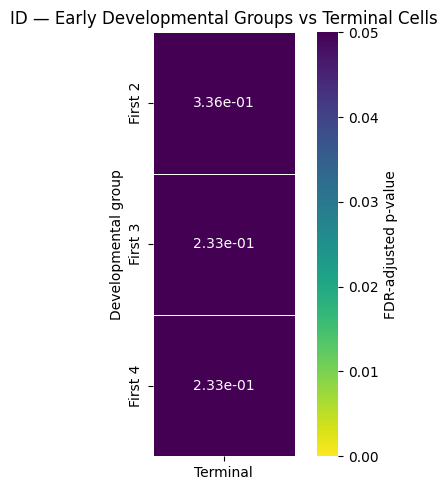


INDIVIDUAL COMPARISONS


,Comparison,n_group,n_terminal,t_stat,p_value,FDR_p
0,Ductal vs Terminal,30,120,1.222968,0.227409,0.454818
1,Ngn3 low vs Terminal,30,120,0.255430,0.799383,0.799383
2,Ngn3 high vs Terminal,30,120,1.408300,0.165985,0.454818
3,Fev+ vs Terminal,30,120,0.915237,0.365486,0.487314


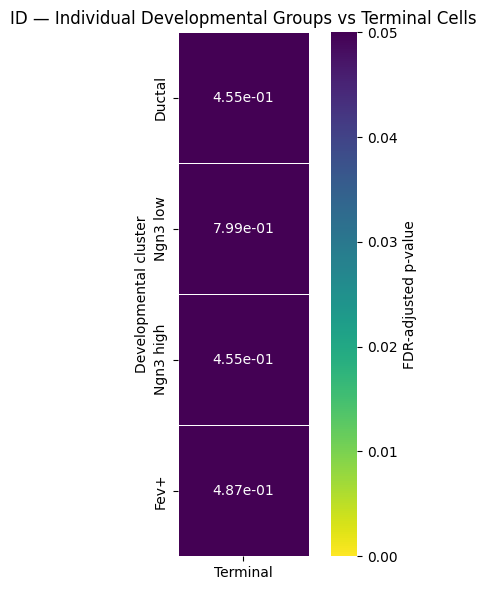

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# DEVELOPMENTAL ORDER
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+",
    "Epsilon",
    "Fev+ Delta",
    "Delta",
    "Fev+ Beta",
    "Beta",
    "Fev+ Alpha",
    "Alpha"
]


# ============================================================
# TERMINAL POPULATION
#
# Epsilon + Delta + Beta + Alpha
# ============================================================

terminal_clusters = [
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha"
]


# ============================================================
# GET CELL-LEVEL ID DISTRIBUTIONS
# ============================================================

id_groups = {
    name: id_results[name].dropna().values
    for name in cluster
    if name in id_results.columns
}


# ============================================================
# COMBINE TERMINAL CELLS
# ============================================================

terminal_values = np.concatenate([
    id_groups[name]
    for name in terminal_clusters
    if name in id_groups
])


print("Terminal cells:", len(terminal_values))


# ============================================================
# HELPER FUNCTION
# ============================================================

def combine_id(clusters):

    return np.concatenate([
        id_groups[name]
        for name in clusters
        if name in id_groups and len(id_groups[name]) > 0
    ])


# ============================================================
# ============================================================
# PART 1
# FIRST 2 / FIRST 3 / FIRST 4 VS TERMINAL
# ============================================================
# ============================================================


first2 = [
    "Ductal",
    "Ngn3 low"
]

first3 = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high"
]

first4 = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+"
]


grouped_comparisons = {
    "First 2": combine_id(first2),
    "First 3": combine_id(first3),
    "First 4": combine_id(first4)
}


# ============================================================
# WELCH T-TESTS
# ============================================================

grouped_results = []

for name, values in grouped_comparisons.items():

    statistic, pvalue = ttest_ind(
        values,
        terminal_values,
        equal_var=False
    )

    grouped_results.append({
        "Comparison": f"{name} vs Terminal",
        "n_group": len(values),
        "n_terminal": len(terminal_values),
        "t_stat": statistic,
        "p_value": pvalue
    })


grouped_results = pd.DataFrame(grouped_results)


# ============================================================
# FDR CORRECTION
# ============================================================

grouped_results["FDR_p"] = multipletests(
    grouped_results["p_value"],
    method="fdr_bh"
)[1]


print("\n========================================")
print("GROUPED COMPARISONS")
print("========================================")

display(grouped_results)


# ============================================================
# CREATE MATRIX FOR HEATMAP
# ============================================================

grouped_matrix = pd.DataFrame(
    grouped_results["FDR_p"].values,
    index=["First 2", "First 3", "First 4"],
    columns=["Terminal"]
)


# ============================================================
# HEATMAP — GROUPED COMPARISONS
# ============================================================

plt.figure(figsize=(5, 5))

sns.heatmap(
    grouped_matrix,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "FDR-adjusted p-value"
    }
)

plt.title(
    "ID — Early Developmental Groups vs Terminal Cells"
)

plt.xlabel("")
plt.ylabel("Developmental group")

plt.tight_layout()
plt.show()


# ============================================================
# ============================================================
# PART 2
# INDIVIDUAL EARLY CLUSTERS VS TERMINAL
# ============================================================
# ============================================================


individual_clusters = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+"
]


# ============================================================
# WELCH T-TESTS
# ============================================================

individual_results = []

for name in individual_clusters:

    values = id_groups[name]

    statistic, pvalue = ttest_ind(
        values,
        terminal_values,
        equal_var=False
    )

    individual_results.append({
        "Comparison": f"{name} vs Terminal",
        "n_group": len(values),
        "n_terminal": len(terminal_values),
        "t_stat": statistic,
        "p_value": pvalue
    })


individual_results = pd.DataFrame(individual_results)


# ============================================================
# FDR CORRECTION
# ============================================================

individual_results["FDR_p"] = multipletests(
    individual_results["p_value"],
    method="fdr_bh"
)[1]


print("\n========================================")
print("INDIVIDUAL COMPARISONS")
print("========================================")

display(individual_results)


# ============================================================
# CREATE MATRIX
# ============================================================

individual_matrix = pd.DataFrame(
    individual_results["FDR_p"].values,
    index=individual_clusters,
    columns=["Terminal"]
)


# ============================================================
# HEATMAP — INDIVIDUAL COMPARISONS
# ============================================================

plt.figure(figsize=(5, 6))

sns.heatmap(
    individual_matrix,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "FDR-adjusted p-value"
    }
)

plt.title(
    "ID — Individual Developmental Groups vs Terminal Cells"
)

plt.xlabel("")
plt.ylabel("Developmental cluster")

plt.tight_layout()
plt.show()